# ส่วนที่ 2: การวิเคราะห์ข้อมูลเชิงสำรวจ (Exploratory Data Analysis: EDA)
หุ้นที่ใช้: **KBANK, CPALL, OR, AOT** ข้อมูลย้อนหลัง 1 ปี

- 2.1 การสำรวจข้อมูลเบื้องต้น (Data Overview)
- 2.2 การจัดการกับความผิดปกติของข้อมูล (Data Cleaning)
- 2.3 การวิเคราะห์เชิงสถิติ (Descriptive Analysis)
- 2.4 การวิเคราะห์เชิงสัมพันธ์ (Correlation & Relationship Analysis)
- 2.5 การวิเคราะห์เชิงภาพ (Visualization Analysis)

### 0. Setup

In [1]:
# !pip install yfinance pandas numpy matplotlib seaborn scipy mplfinance   # รันครั้งแรกหากยังไม่มีไลบรารี
import warnings                         # ไว้ปิด warning ที่ไม่จำเป็น
warnings.filterwarnings("ignore")       # ปิด warning ไม่ให้รกตอนรัน

import numpy as np                      # คำนวณตัวเลข / array / matrix
import pandas as pd                     # จัดการข้อมูลแบบตาราง
import matplotlib.pyplot as plt         # วาดกราฟพื้นฐาน
import seaborn as sns                   # วาดกราฟเชิงสถิติ
import yfinance as yf                   # ดึงข้อมูลหุ้นจาก Yahoo Finance

pd.set_option("display.float_format", lambda x: f"{x:,.4f}")   # แสดงทศนิยม 4 ตำแหน่ง
pd.set_option("display.width", 160)                            # ตารางกว้างขึ้น ไม่ตัดคอลัมน์
sns.set_theme(style="whitegrid", palette="deep")               # ธีมกราฟพื้นขาวมีกริด
plt.rcParams["figure.dpi"] = 110                               # กราฟคมขึ้น

TICKERS = ["KBANK", "CPALL", "OR", "AOT"]                      # หุ้นที่กลุ่มเลือก (กลุ่มละ 1 ตัว)
SECTOR_OF = {"KBANK": "Finance & Banking", "CPALL": "Consumer & Retail",
             "OR": "Energy & Utilities", "AOT": "Transportation"}   # หุ้นแต่ละตัวอยู่กลุ่มไหน
SYMBOLS = [f"{t}.BK" for t in TICKERS]                         # หุ้นไทยใน yfinance ต้องเติม .BK
RF = 0.02                                                      # risk-free rate 2% ต่อปี (พันธบัตรรัฐบาลไทย)
TRADING_DAYS = 252                                             # จำนวนวันทำการต่อปี

from scipy import stats                 # ใช้ทดสอบสถิติ เช่น skew, kurtosis, normality test

---
## 2.1 การสำรวจข้อมูลเบื้องต้น (Data Overview)

In [2]:
raw = yf.download(SYMBOLS, period="1y", auto_adjust=True, progress=False)   # ดึง OHLCV 1 ปี
raw.columns = raw.columns.set_levels([c.replace(".BK", "") for c in raw.columns.levels[1]], level=1)  # ตัด .BK ออกจากชื่อหุ้น
print("ขนาดข้อมูล (แถว, คอลัมน์):", raw.shape)
print("ช่วงวันที่:", raw.index.min().date(), "->", raw.index.max().date())
print("ระดับคอลัมน์:", raw.columns.names, "| ประเภทราคา:", raw.columns.levels[0].tolist())
raw.head()

ขนาดข้อมูล (แถว, คอลัมน์): (242, 20)
ช่วงวันที่: 2025-11-05 -> 2026-11-05
ระดับคอลัมน์: ['Price', 'Ticker'] | ประเภทราคา: ['Close', 'High', 'Low', 'Open', 'Volume']


Price        Close                             High                              Low                             Open                             Volume  \
Ticker         AOT   CPALL    KBANK      OR     AOT   CPALL    KBANK      OR     AOT   CPALL    KBANK      OR     AOT   CPALL    KBANK      OR       AOT   
Date                                                                                                                                                       
2025-11-05 39.4000 43.3681 169.4732 13.8652 39.6463 44.0909 172.2591 13.9608 38.6613 43.1272 169.0089 13.7695 38.9075 44.0909 171.3305 13.8652  16353300   
2025-11-06 39.6463 43.3681 169.9375 13.8652 39.6463 43.8500 170.8662 14.0564 38.9075 42.8863 168.0803 13.6739 39.4000 43.8500 169.9375 14.0564  14557300   
2025-11-07 40.3850 43.3681 167.1517 13.5783 40.6313 43.8500 169.9375 13.9608 38.9075 43.1272 166.6874 13.4827 39.4000 43.3681 169.4732 13.7695  28952200   
2025-11-10 41.1237 43.8500 169.0089 13.6739 41.3700 44.3319 169.4732 13.7695 40.1387 43.3681 167.1517 13.4827 40.6312 43.3681 167.6160 13.6739  24210500   
2025-11-11 41.8625 43.3681 168.0803 13.5783 42.1087 44.0909 170.4019 13.8652 41.1237 43.3681 167.1517 13.4827 41.3700 43.8500 169.4732 13.7695  28864700   

Price                                     
Ticker         CPALL     KBANK        OR  
Date                                      
2025-11-05  17057600  18393100  10809900  
2025-11-06  20165600  13291000  12323100  
2025-11-07  17608000  10888800  18290100  
2025-11-10  16407400  10172700   9097300  
2025-11-11  29289000  11730300   9960700

In [3]:
close = raw["Close"][TICKERS]        # เลือกเฉพาะราคาปิด
volume = raw["Volume"][TICKERS]      # และปริมาณซื้อขาย
print("ชนิดข้อมูลของแต่ละคอลัมน์:"); print(close.dtypes)
print("\nตัวอย่าง 5 วันล่าสุด:"); display(close.tail())

ชนิดข้อมูลของแต่ละคอลัมน์:
Ticker
KBANK    float64
CPALL    float64
OR       float64
AOT      float64
dtype: object

ตัวอย่าง 5 วันล่าสุด:


Ticker,KBANK,CPALL,OR,AOT
Date,,,,
2026-10-30,246.0000,43.7500,12.5000,59.7500
2026-11-02,242.0000,43.7500,12.5000,60.0000
2026-11-03,243.0000,44.0000,12.5000,59.5000
2026-11-04,244.0000,44.0000,12.5000,60.5000
2026-11-05,NaN,NaN,NaN,NaN


---
## 2.2 การจัดการกับความผิดปกติของข้อมูล (Data Cleaning)
ตรวจ 4 อย่าง: ค่าว่าง (Missing), วันที่ซ้ำ (Duplicate), ราคา/ปริมาณผิดปกติ (≤ 0) และค่าผิดปกติทางสถิติ (Outlier)

In [4]:
# 1) Missing values
missing = pd.DataFrame({"Missing (Close)": close.isna().sum(), "Missing (Volume)": volume.isna().sum()})
display(missing)
print("แถวที่มีค่าว่าง:"); display(close[close.isna().any(axis=1)])   # ดูว่าว่างวันไหน

,Missing (Close),Missing (Volume)
Ticker,,
KBANK,1,0
CPALL,1,0
OR,1,0
AOT,1,0


แถวที่มีค่าว่าง:


Ticker,KBANK,CPALL,OR,AOT
Date,,,,
2026-11-05,NaN,NaN,NaN,NaN


In [5]:
# 2) Duplicate dates และ 3) ค่าที่เป็นไปไม่ได้
print("จำนวนวันที่ซ้ำ:", close.index.duplicated().sum())
print("จำนวนราคา <= 0:", (close <= 0).sum().sum())
print("จำนวนวันที่ volume = 0 (ไม่มีการซื้อขาย):"); print((volume == 0).sum())

จำนวนวันที่ซ้ำ: 0
จำนวนราคา <= 0: 0
จำนวนวันที่ volume = 0 (ไม่มีการซื้อขาย):
Ticker
KBANK    0
CPALL    1
OR       0
AOT      0
dtype: int64


In [6]:
# วิธีจัดการ: ตัดแถวที่ว่างทั้งแถว -> forward fill (ใช้ราคาวันก่อนหน้า) -> ตัดที่ยังว่างอยู่
before = len(close)
close = close.dropna(how="all").ffill().dropna()
volume = volume.loc[close.index].fillna(0)            # ให้ volume ใช้วันเดียวกับราคา
print(f"จำนวนแถวก่อน {before} -> หลัง {len(close)} | ค่าว่างคงเหลือ: {close.isna().sum().sum()}")

จำนวนแถวก่อน 242 -> หลัง 241 | ค่าว่างคงเหลือ: 0


In [7]:
# 4) Outlier ของผลตอบแทนรายวัน ด้วย Z-score และ IQR
ret = close.pct_change().dropna()                     # ผลตอบแทนรายวัน
z = (ret - ret.mean()) / ret.std()                    # Z-score = ห่างจากค่าเฉลี่ยกี่ SD
z_out = (z.abs() > 3).sum()                           # |z| > 3 ถือเป็นค่าผิดปกติ
q1, q3 = ret.quantile(0.25), ret.quantile(0.75)       # ควอไทล์ที่ 1 และ 3
iqr = q3 - q1                                         # ช่วงระหว่างควอไทล์
iqr_out = ((ret < q1 - 1.5 * iqr) | (ret > q3 + 1.5 * iqr)).sum()   # นอกช่วง 1.5 IQR
display(pd.DataFrame({"Outliers |Z|>3": z_out, "Outliers 1.5*IQR": iqr_out}))
print("วันที่ผลตอบแทนผิดปกติมากที่สุดของแต่ละหุ้น:")
display(pd.DataFrame({"Date": ret.abs().idxmax().dt.date, "Return": [ret.loc[ret[c].abs().idxmax(), c] for c in TICKERS]}, index=TICKERS))

,Outliers |Z|>3,Outliers 1.5*IQR
Ticker,,
KBANK,3,12
CPALL,1,8
OR,4,15
AOT,3,14


วันที่ผลตอบแทนผิดปกติมากที่สุดของแต่ละหุ้น:


,Date,Return
KBANK,2026-07-02,0.0688
CPALL,2026-05-14,0.0686
OR,2026-03-26,0.0789
AOT,2025-12-04,0.1158


**หมายเหตุ:** outlier ของผลตอบแทนหุ้นมักเป็นเหตุการณ์จริง (ประกาศงบ, ข่าว, XD) ไม่ใช่ข้อมูลผิด จึง **ไม่ตัดทิ้ง** แต่ใช้เพื่อทำความเข้าใจความเสี่ยงหางยาว (fat tails) — ถ้าตัดทิ้งจะทำให้ประเมินความเสี่ยงต่ำเกินจริง

---
## 2.3 การวิเคราะห์เชิงสถิติ (Descriptive Analysis)

In [8]:
print("สถิติพื้นฐานของราคาปิด"); display(close.describe().T)
print("สถิติพื้นฐานของผลตอบแทนรายวัน"); display(ret.describe().T)

สถิติพื้นฐานของราคาปิด


,count,mean,std,min,25%,50%,75%,max
Ticker,,,,,,,,
KBANK,241.0000,204.0457,29.5951,167.1517,177.8308,193.4274,235.0000,258.0000
CPALL,241.0000,44.7997,2.3431,39.5132,42.8863,44.5000,46.5000,52.5236
OR,241.0000,12.4478,0.6757,10.8398,12.1094,12.4000,12.7177,14.9170
AOT,241.0000,55.6816,6.5486,39.4000,51.7500,55.0000,61.5000,67.0000


สถิติพื้นฐานของผลตอบแทนรายวัน


,count,mean,std,min,25%,50%,75%,max
Ticker,,,,,,,,
KBANK,240.0000,0.0016,0.0128,-0.0397,-0.0051,0.0000,0.0083,0.0688
CPALL,240.0000,0.0002,0.0154,-0.0413,-0.0084,0.0000,0.0103,0.0686
OR,240.0000,-0.0003,0.0181,-0.0746,-0.0081,0.0000,0.0081,0.0789
AOT,240.0000,0.0020,0.0216,-0.0583,-0.0096,0.0000,0.0122,0.1158


In [9]:
# สถิติเชิงลึก: Skewness (ความเบ้), Kurtosis (ความโด่ง) และ Jarque-Bera test (ทดสอบว่าเป็นการแจกแจงปกติไหม)
desc = pd.DataFrame({
    "Mean (daily)": ret.mean(),                                   # ผลตอบแทนเฉลี่ยต่อวัน
    "Median (daily)": ret.median(),                               # ค่ากลาง
    "Std (daily)": ret.std(),                                     # ความผันผวนต่อวัน
    "Skewness": ret.skew(),                                       # < 0 = หางซ้ายยาว (ขาดทุนแรงบ่อยกว่า)
    "Excess Kurtosis": ret.kurt(),                                # > 0 = หางหนากว่าการแจกแจงปกติ
    "Min": ret.min(), "Max": ret.max(),
    "JB p-value": [stats.jarque_bera(ret[c])[1] for c in TICKERS],   # p < 0.05 = ไม่ใช่การแจกแจงปกติ
})
desc["Normal?"] = np.where(desc["JB p-value"] < 0.05, "No", "Yes")
desc

,Mean (daily),Median (daily),Std (daily),Skewness,Excess Kurtosis,Min,Max,JB p-value,Normal?
Ticker,,,,,,,,,
KBANK,0.0016,0.0000,0.0128,0.5949,3.4908,-0.0397,0.0688,0.0000,No
CPALL,0.0002,0.0000,0.0154,0.3132,1.8108,-0.0413,0.0686,0.0000,No
OR,-0.0003,0.0000,0.0181,0.4102,4.1526,-0.0746,0.0789,0.0000,No
AOT,0.0020,0.0000,0.0216,1.0478,4.8858,-0.0583,0.1158,0.0000,No


**การตีความ:** ถ้า Excess Kurtosis > 0 และ JB p-value < 0.05 แปลว่าผลตอบแทนมี *fat tails* — เหตุการณ์ราคาขึ้น/ลงแรงเกิดบ่อยกว่าที่การแจกแจงปกติคาด การใช้ VaR แบบ Parametric (สมมติ normal) จึงอาจประเมินความเสี่ยงต่ำไป

---
## 2.4 การวิเคราะห์เชิงสัมพันธ์ (Correlation & Relationship Analysis)

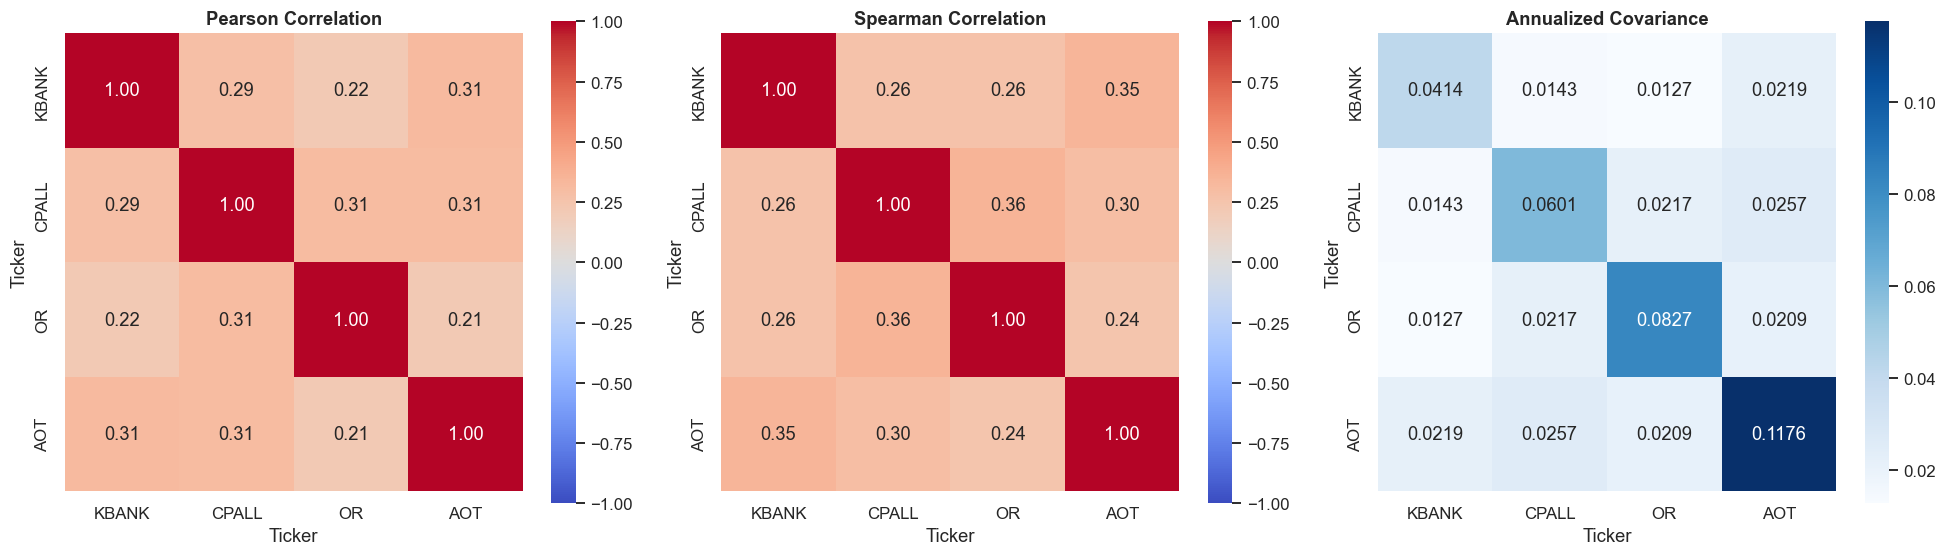

In [10]:
corr = ret.corr()                                     # Pearson correlation ของผลตอบแทน
cov = ret.cov() * TRADING_DAYS                        # covariance ต่อปี
spearman = ret.corr(method="spearman")                # Spearman (ใช้อันดับ ทนต่อ outlier)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True, ax=axes[0])
axes[0].set_title("Pearson Correlation", fontweight="bold")
sns.heatmap(spearman, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True, ax=axes[1])
axes[1].set_title("Spearman Correlation", fontweight="bold")
sns.heatmap(cov, annot=True, fmt=".4f", cmap="Blues", square=True, ax=axes[2])
axes[2].set_title("Annualized Covariance", fontweight="bold")
plt.tight_layout(); plt.show()

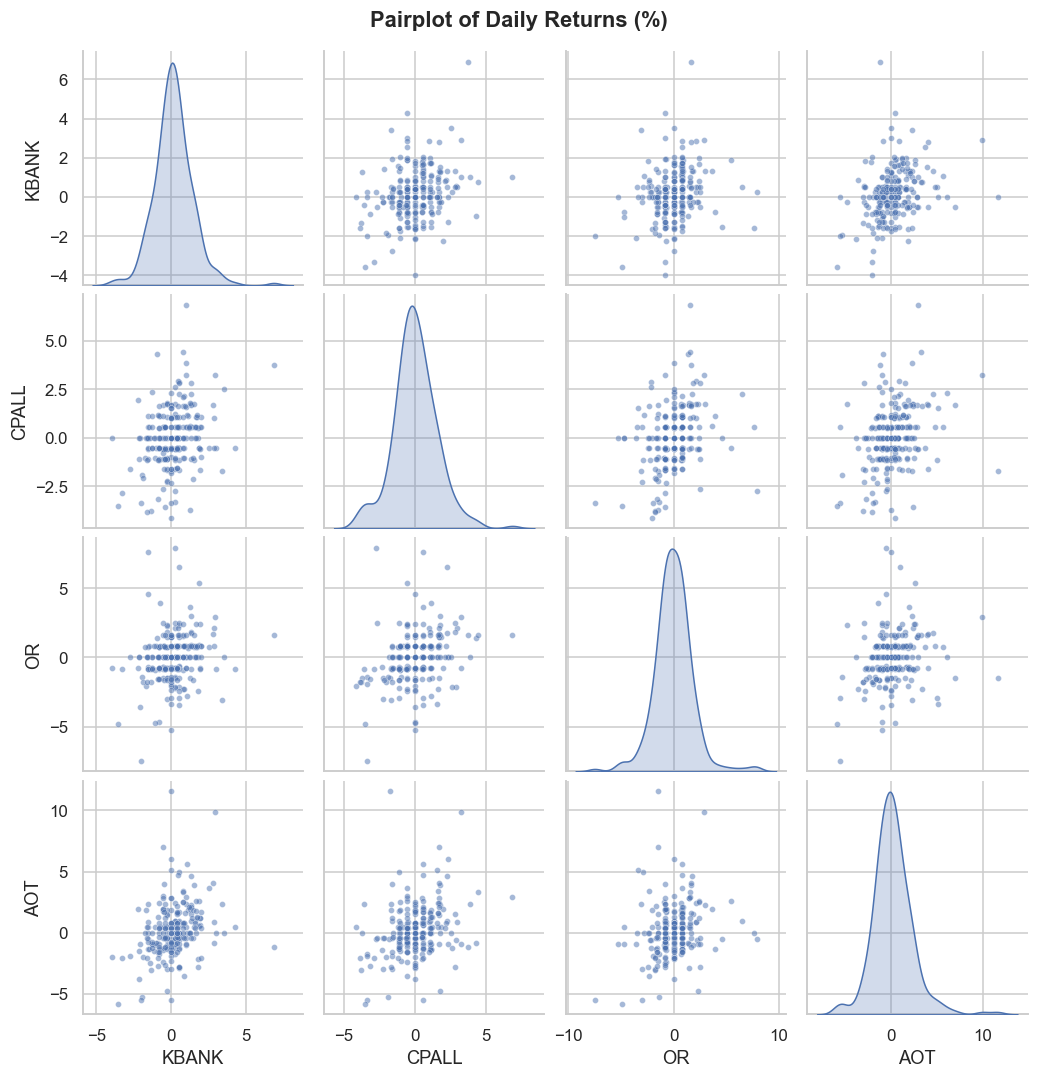

In [11]:
# Pairplot: ดู scatter ความสัมพันธ์ของผลตอบแทนทุกคู่ + การกระจายของแต่ละตัว (แนวทแยง)
g = sns.pairplot(ret * 100, diag_kind="kde", plot_kws={"alpha": 0.5, "s": 15}, height=2.4)
g.figure.suptitle("Pairplot of Daily Returns (%)", y=1.02, fontweight="bold")
plt.show()

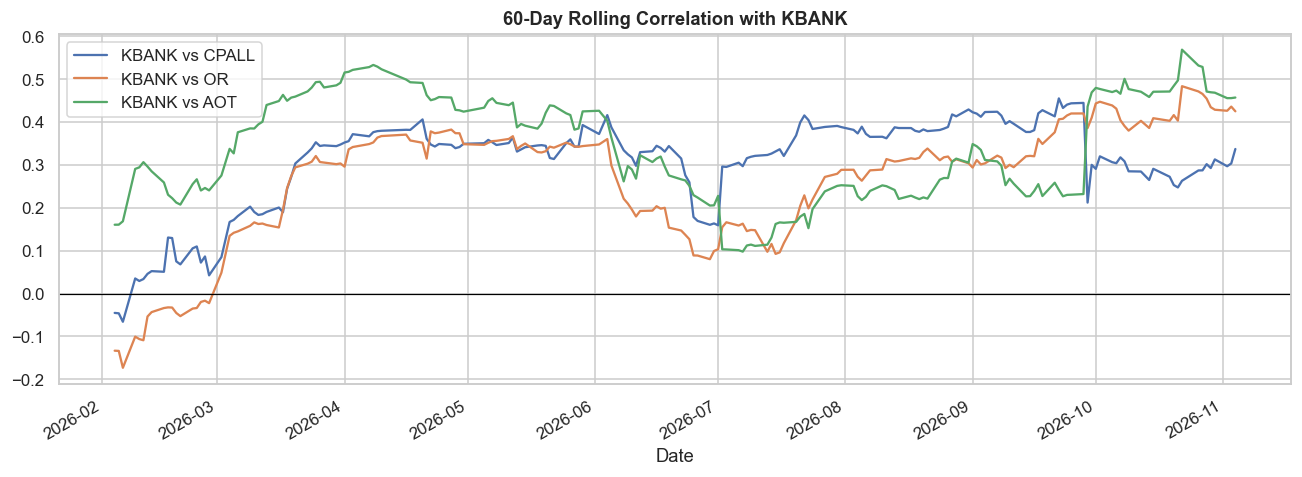

In [12]:
# Rolling correlation 60 วัน: ความสัมพันธ์เปลี่ยนไปตามเวลาหรือไม่
fig, ax = plt.subplots(figsize=(12, 4.5))
for other in ["CPALL", "OR", "AOT"]:
    ret["KBANK"].rolling(60).corr(ret[other]).plot(ax=ax, label=f"KBANK vs {other}")   # corr ในหน้าต่าง 60 วัน
ax.axhline(0, color="black", lw=0.8)
ax.set_title("60-Day Rolling Correlation with KBANK", fontweight="bold"); ax.legend()
plt.tight_layout(); plt.show()

In [13]:
# ความสัมพันธ์ระหว่างปริมาณซื้อขายกับขนาดการเปลี่ยนแปลงราคา (|return|)
vol_rel = pd.DataFrame({t: [ret[t].abs().corr(volume[t].loc[ret.index])] for t in TICKERS}, index=["corr(|Return|, Volume)"])
vol_rel      # ค่าบวก = วันที่ราคาขยับแรงมักมี volume สูง

,KBANK,CPALL,OR,AOT
"corr(|Return|, Volume)",0.5717,0.5978,0.6393,0.7075


**การตีความ:** correlation ระหว่างหุ้นต่างกลุ่มอยู่ในระดับต่ำ–ปานกลาง แปลว่าการถือรวมกันช่วย **กระจายความเสี่ยง** ได้ (ความเสี่ยงพอร์ตต่ำกว่าค่าเฉลี่ยถ่วงน้ำหนักของความเสี่ยงรายตัว) และ rolling correlation แสดงว่าความสัมพันธ์ไม่คงที่ — ช่วงตลาดผันผวนมักมี correlation สูงขึ้น

---
## 2.5 การวิเคราะห์เชิงภาพ (Visualization Analysis)

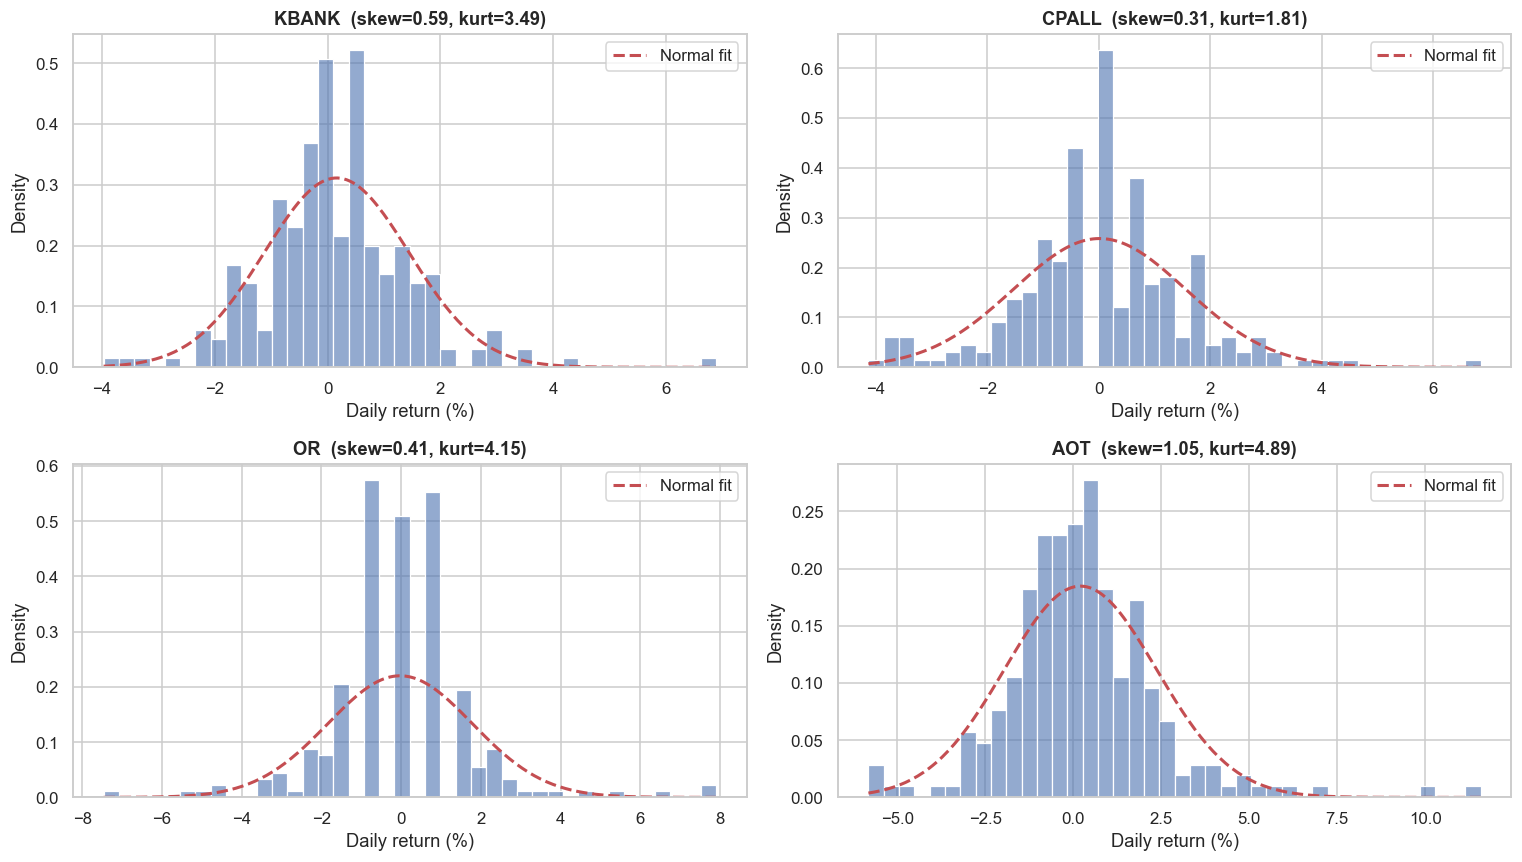

In [14]:
# Histogram ของผลตอบแทน + เส้นการแจกแจงปกติที่มี mean/std เท่ากัน เพื่อดูว่าหางหนากว่าไหม
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for ax, t in zip(axes.flat, TICKERS):
    r = ret[t] * 100
    sns.histplot(r, bins=40, stat="density", ax=ax, color="#4C72B0", alpha=0.6)   # histogram แบบ density
    x = np.linspace(r.min(), r.max(), 200)
    ax.plot(x, stats.norm.pdf(x, r.mean(), r.std()), "r--", lw=2, label="Normal fit")   # เส้น normal เปรียบเทียบ
    ax.set_title(f"{t}  (skew={r.skew():.2f}, kurt={r.kurt():.2f})", fontweight="bold")
    ax.set_xlabel("Daily return (%)"); ax.legend()
plt.tight_layout(); plt.show()

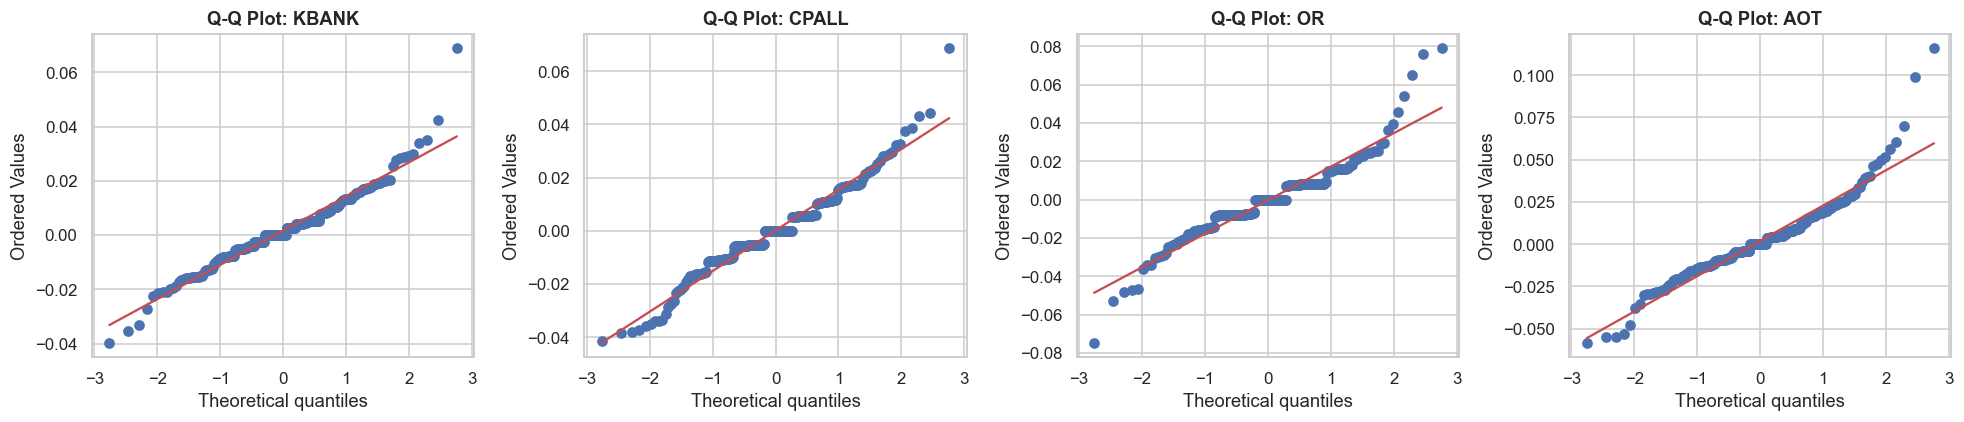

In [15]:
# Q-Q plot: ถ้าจุดอยู่บนเส้นตรงแปลว่าใกล้การแจกแจงปกติ ถ้าปลายเบี่ยงออก = fat tails
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, t in zip(axes, TICKERS):
    stats.probplot(ret[t], dist="norm", plot=ax)       # เทียบ quantile จริงกับ quantile ของ normal
    ax.set_title(f"Q-Q Plot: {t}", fontweight="bold")
plt.tight_layout(); plt.show()

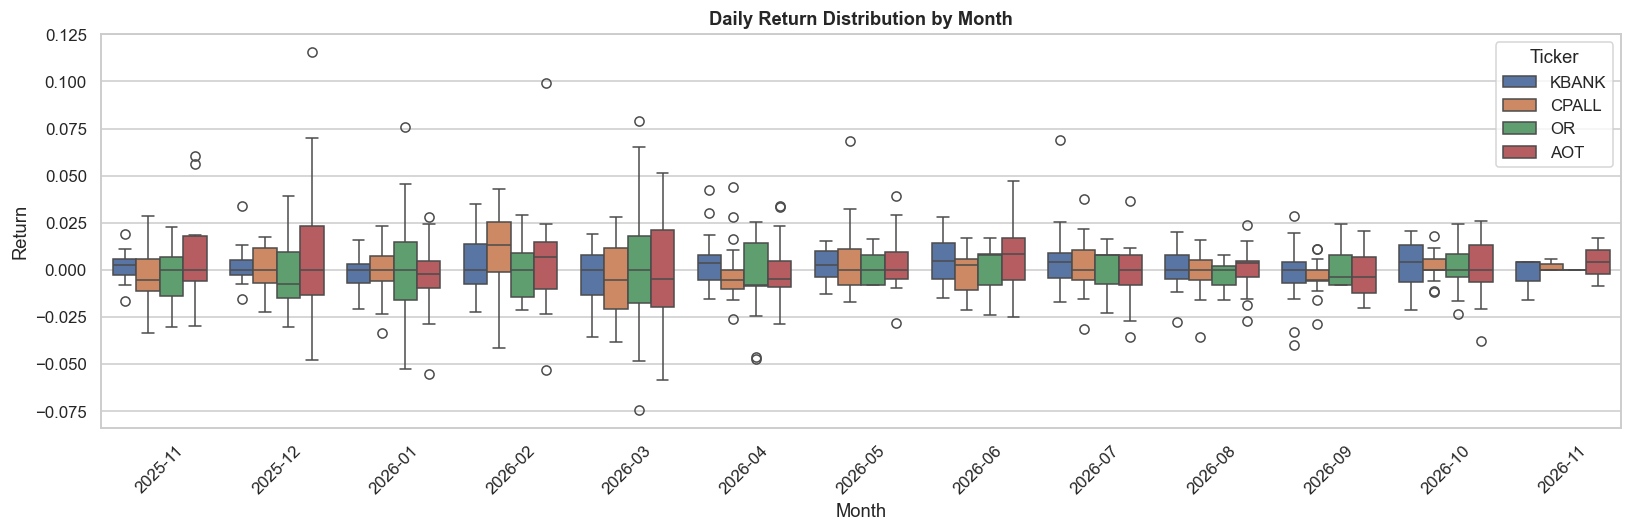

In [16]:
# Boxplot ผลตอบแทนรายเดือน: ดูว่าเดือนไหนผันผวน
mret = ret.copy(); mret["Month"] = mret.index.to_period("M").astype(str)        # เพิ่มคอลัมน์เดือน
long = mret.melt(id_vars="Month", var_name="Ticker", value_name="Return")      # แปลงเป็น long format ให้ seaborn ใช้
plt.figure(figsize=(15, 5))
sns.boxplot(data=long, x="Month", y="Return", hue="Ticker")
plt.xticks(rotation=45); plt.title("Daily Return Distribution by Month", fontweight="bold")
plt.tight_layout(); plt.show()

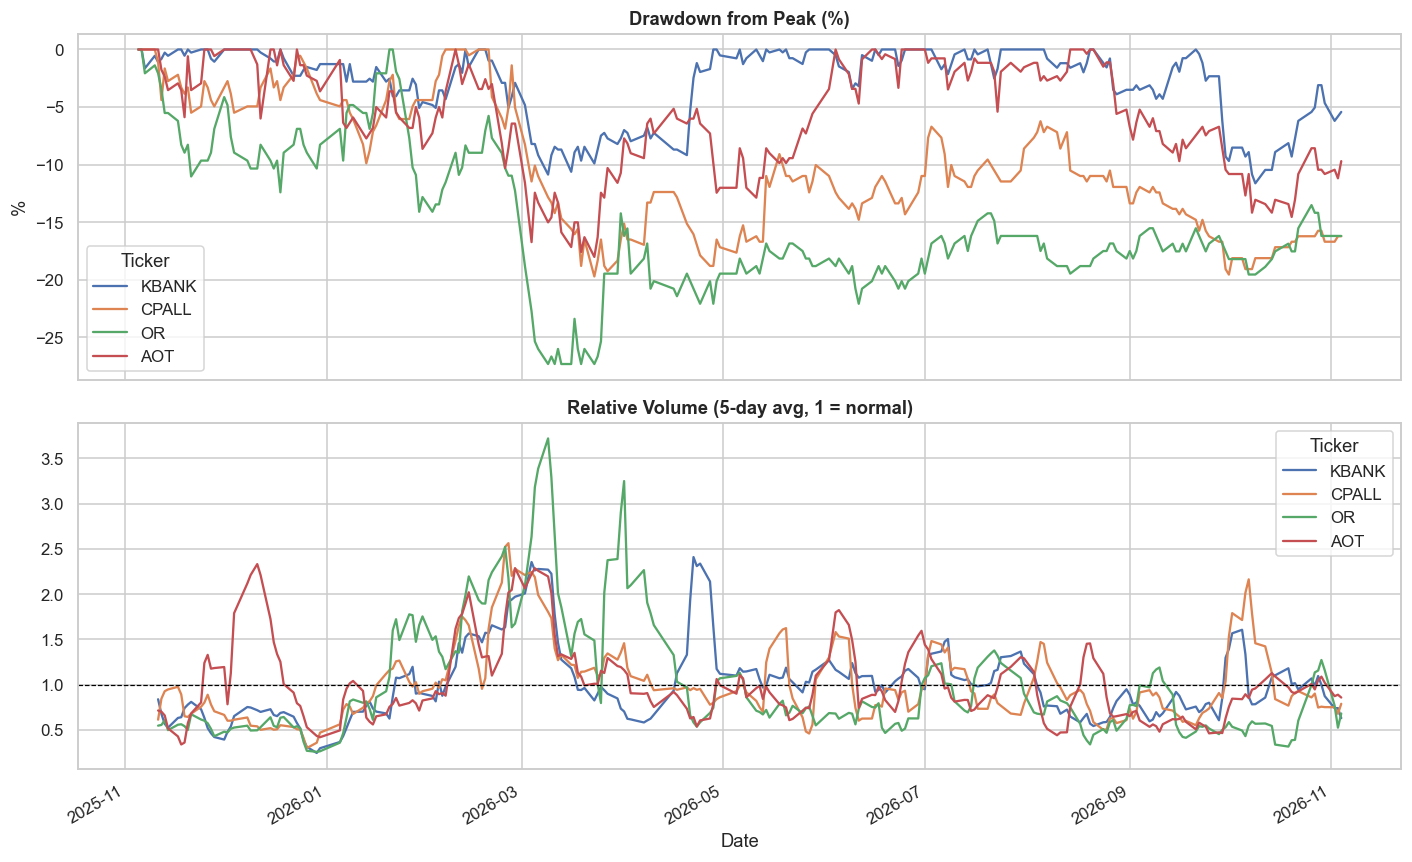

Max Drawdown:
Ticker
KBANK    -11.63 %
CPALL    -19.72 %
OR       -27.33 %
AOT      -18.03 %
dtype: object


In [17]:
# Drawdown: ราคาลดลงจากจุดสูงสุดก่อนหน้ากี่ %  และ volume รายวัน
fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharex=True)
drawdown = close / close.cummax() - 1                 # cummax = จุดสูงสุดสะสม
(drawdown * 100).plot(ax=axes[0])
axes[0].set_title("Drawdown from Peak (%)", fontweight="bold"); axes[0].set_ylabel("%")
(volume / volume.mean()).rolling(5).mean().plot(ax=axes[1])   # volume เทียบค่าเฉลี่ย (1 = ปกติ) เกลี่ย 5 วัน
axes[1].axhline(1, color="black", ls="--", lw=0.8)
axes[1].set_title("Relative Volume (5-day avg, 1 = normal)", fontweight="bold")
plt.tight_layout(); plt.show()
print("Max Drawdown:"); print((drawdown.min() * 100).round(2).astype(str) + " %")

### สรุปส่วนที่ 2
1. ข้อมูลจาก yfinance มีค่าว่างน้อย (มักเป็นวันล่าสุดที่ตลาดยังไม่ปิด) จัดการด้วย `dropna` + `ffill`
2. ผลตอบแทนรายวันไม่เป็นการแจกแจงปกติ (fat tails) ดูได้จาก Kurtosis, JB test และ Q-Q plot
3. หุ้นต่างกลุ่มมี correlation ต่ำ จึงเหมาะสำหรับนำมาสร้างพอร์ตกระจายความเสี่ยงในส่วนที่ 3